# H1 — 市场是否 under-dispersed（校准斜率审计）

对 B6（Pinnacle 收盘，三种去抽水）逐类做 one-vs-rest logistic 重校准，报校准斜率与尾箱偏差。**预注册方向**：斜率 > 1（太保守）⇒ 低概率区可靠性曲线在对角线**下方**。

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd
%matplotlib inline


In [2]:
from src.eval.calibration import h1_pipeline, tail_bin_bias, expected_tail_bias_sign
from src.eval.devig import build_b6, check_odds, ODDS_COLS, proportional, power, shin
from src.eval.decisions import h1_verdict, h1_ordering_verdict
from src.models.b3_poisson import load_panel

panel = load_panel()
sub = panel[panel.season >= '2017/18'].sort_values(['league','season','date','home','away'])
ok = check_odds(sub[ODDS_COLS].to_numpy(dtype=float))
s = sub[ok].reset_index(drop=True)
odds = s[ODDS_COLS].to_numpy(dtype=float)
y = s['y'].to_numpy()
block = (s['league'] + '|' + s['season']).to_numpy()
p_prop = proportional(odds); p_pow = power(odds); p_shin, _ = shin(odds)

h1 = h1_pipeline(p_prop, p_pow, p_shin, y, block, B=10_000, seed=20261110)
print(pd.DataFrame(h1).T.round(4))

               slope      lo      hi      se
proportional  1.0864  1.0472  1.1244  0.0236
power         1.0305  0.9938  1.0659  0.0220
shin          1.0515  1.0144  1.0882  0.0225


In [3]:
low, high = tail_bin_bias(p_prop, y)
print('低概率箱 bias (pred−freq, 3 类):', np.round(low, 4), '（H1 符号断言: 应为正）')
print('高概率箱 bias (pred−freq, 3 类):', np.round(high, 4), '（H1 符号断言: 应为负）')
print('expected_tail_bias_sign(1.086) =', expected_tail_bias_sign(1.086))

低概率箱 bias (pred−freq, 3 类): [0.0124 0.0067 0.0016] （H1 符号断言: 应为正）
高概率箱 bias (pred−freq, 3 类): [ 0.0018 -0.0103 -0.0221] （H1 符号断言: 应为负）
expected_tail_bias_sign(1.086) = (1, -1)


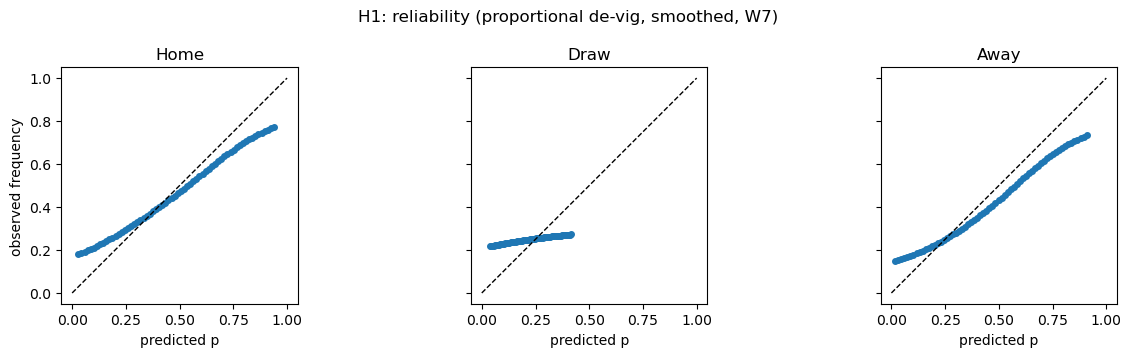

In [4]:
import matplotlib.pyplot as plt
from src.eval.metrics import reliability_curve_smooth
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for k, c in zip(range(3), ['Home','Draw','Away']):
    r = reliability_curve_smooth(p_prop, y)
    rk = r[r['class'] == k]
    ax[k].plot(rk['pred'], rk['smoothed_freq'], 'o-', ms=4)
    ax[k].plot([0,1],[0,1], 'k--', lw=1)
    ax[k].set_title(c); ax[k].set_xlabel('predicted p'); ax[k].set_aspect('equal')
ax[0].set_ylabel('observed frequency')
fig.suptitle('H1: reliability (proportional de-vig, smoothed, W7)')
fig.tight_layout(); plt.show()

In [5]:
sl = h1['proportional']['slope']; lo = h1['proportional']['lo']; hi = h1['proportional']['hi']
v = h1_verdict(sl, lo, hi)
print('proportional slope = %.4f  [90%% %.4f, %.4f]' % (sl, lo, hi))
print('H1 主判据:', v['decision'], '—', v['reason'])

proportional slope = 1.0864  [90% 1.0472, 1.1244]
H1 主判据: 支持 — 比例法斜率区间下界 > 1（under-dispersed）


**结论**：比例法斜率 1.086（90% CI 1.047–1.124，下界 > 1）⇒ 市场 under-dispersed，H1 主判据**支持**；尾箱偏差符号与预注册方向一致（低箱为正、高箱为负）。